# Distributed MDO from Scratch: ATC and NHATC with Augmented Lagrangian Coordination

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L11/L11_atc_nhatc_from_scratch.ipynb)
### MECH 559 - Systems Optimization - L11
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *Distributed MDO* section of the lecture. Monolithic MDO puts the
whole problem in **one** optimizer. Distributed MDO gives each discipline **its own**
optimizer and coordinates them through penalties on their disagreement. Before using the
DMDO package (next notebook), we build both coordination schemes from the slides ourselves,
in about 30 lines each, so that nothing DMDO does later is a black box.

- **ATC** (analytical target cascading): a *system* problem sets targets; *subsystems* try to
  meet them. A manager and two teams.
- **NHATC** (non-hierarchical ATC): no system problem; the subsystems negotiate directly,
  pair by pair. A group of peers.

## Learning objectives

1. Decompose a coupled problem into subproblems: shared, local and coupling variables.
2. Implement the augmented Lagrangian penalty $\phi(\mathbf{h}) = \mathbf{v}^\mathrm{T}\mathbf{h} + \|\mathbf{w}\circ\mathbf{h}\|_2^2$
   and the method-of-multipliers updates for $\mathbf{v}$ and $\mathbf{w}$.
3. Run ATC and NHATC and read their convergence histories.
4. Explain the trade-off controlled by the penalty growth factor $\beta$, and why the initial
   weights matter on non-convex problems.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"atc": "#1D5FA8", "nhatc": "#D1495B", "ref": "#2A9D5C"}
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

F_REF = 4.98933       # reference optimum from the monolithic notebook (MDF/IDF with SLSQP)

---
## 1. Decomposing the running example

$$
\min_{u, v, w}\ u + v + a + b \quad \text{s.t.}\quad w + b - 10 \le 0,
\qquad a = \mathcal{U}_1(u, v; b), \quad b = \mathcal{U}_2(u, w; a)
$$

Sort every quantity by **who owns it**:

| Quantity | Type | Owner |
|---|---|---|
| $u$ | **shared** design variable (both disciplines use it) | both: each keeps a *copy* |
| $v$ | **local** design variable | subproblem 1 |
| $w$ | **local** design variable | subproblem 2 |
| $a$ | **coupling** variable, output of discipline 1, input of 2 | computed by 1, *target* in 2 |
| $b$ | **coupling** variable, output of discipline 2, input of 1 | computed by 2, *target* in 1 |
| $g = w + b - 10 \le 0$ | **local** constraint | subproblem 2 |

Every copy or target introduces a **consistency constraint** $h = 0$ (copy = original,
target = response). Distributed MDO relaxes these constraints with a penalty and drives them
to zero over the outer iterations.

In [2]:
def U1(u, v, b):
    return np.log(u) + np.log(v) + np.log(b)


def U2(u, w, a):
    return 1.0 / u + 1.0 / w + 1.0 / a


LO, HI = 1e-3, 10.0       # bounds on the design variables
C_LO = 0.1                # lower bound on the coupling variables a, b (physical branch, see the MDF notebook)

---
## 2. The augmented Lagrangian penalty and its updates

For a vector of inconsistencies $\mathbf{h}$, the penalty used by ATC and NHATC is

$$
\phi(\mathbf{h}) = \underbrace{\mathbf{v}^\mathrm{T}\mathbf{h}}_{\text{"price" of disagreement}}
+ \underbrace{\|\mathbf{w}\circ\mathbf{h}\|_2^2}_{\text{"stiffness"}} .
$$

After each outer iteration $k$ the weights are updated by the **method of multipliers**:

$$
\mathbf{v}^{(k)} = \mathbf{v}^{(k-1)} + 2\,\mathbf{w}^{(k-1)}\circ\mathbf{w}^{(k-1)}\circ\mathbf{h}^{(k-1)},
\qquad
w_j^{(k)} = \begin{cases} w_j^{(k-1)} & \text{if } |h_j^{(k-1)}| \le \gamma\,|h_j^{(k-2)}| \\
                           \beta\,w_j^{(k-1)} & \text{otherwise.} \end{cases}
$$

$\mathbf{v}$ learns the *price* of each disagreement (a Lagrange multiplier estimate). If a
disagreement does not shrink by at least a factor $\gamma$, its penalty gets $\beta$ times
**stiffer**.

In [3]:
class Penalty:
    """Augmented Lagrangian penalty for a fixed list of named consistency constraints."""

    def __init__(self, names, w0=1.0):
        self.names = list(names)
        self.v = dict.fromkeys(self.names, 0.0)
        self.w = dict.fromkeys(self.names, w0)
        self.h_old = None

    def __call__(self, **h):
        """phi for the inconsistencies passed by name, e.g. pen(u=u1 - u, a=a_hat - a_t)."""
        return sum(self.v[n] * h[n] + (self.w[n] * h[n]) ** 2 for n in h)

    def update(self, h, beta, gamma):
        for n in self.names:
            self.v[n] += 2 * self.w[n] ** 2 * h[n]
            if self.h_old is not None and abs(h[n]) > gamma * abs(self.h_old[n]):
                self.w[n] *= beta
        self.h_old = dict(h)


def slsqp(fun, x0, bounds, cons=()):
    return minimize(fun, x0, method="SLSQP", bounds=bounds, constraints=list(cons),
                    options={"ftol": 1e-10, "maxiter": 200}).x

---
## 3. NHATC: peers negotiating directly

There is no system problem. Each subproblem owns a **copy** of the shared variable and a
**target** for the coupling variable it receives, and it carries a share of the objective:

$$
\begin{aligned}
\text{SP}_1:\ \min_{u_1, v, b^t}\ & u_1 + v + \hat a + \phi\big(u_1 - u_2,\ a^t - \hat a,\ b^t - \hat b\big),
& \hat a &= \mathcal{U}_1(u_1, v; b^t) \\
\text{SP}_2:\ \min_{u_2, w, a^t}\ & \hat b + \phi\big(u_1 - u_2,\ a^t - \hat a,\ b^t - \hat b\big)
\quad \text{s.t. } w + \hat b - 10 \le 0, & \hat b &= \mathcal{U}_2(u_2, w; a^t)
\end{aligned}
$$

Each subproblem treats the other's variables as **fixed** at their latest values. We solve
SP1, then SP2 (Gauss-Seidel over subproblems), then update the penalty weights: one
**outer iteration**. Both subproblems also keep their computed coupling variable within its
bounds, which is exactly what DMDO does automatically.

In [4]:
def nhatc(beta=2.0, gamma=0.25, w0=1.0, max_outer=150, tol=1e-6):
    u1, v, bt = 1.0, 1.0, 1.0           # SP1: copy of u, local v, target for b
    u2, w, at = 1.0, 1.0, 1.0           # SP2: copy of u, local w, target for a
    a_hat, b_hat = U1(u1, v, bt), U2(u2, w, at)
    pen = Penalty(["u", "a", "b"], w0)
    hist = []
    for k in range(1, max_outer + 1):
        # --- subproblem 1 (SP2's variables fixed) ---
        def sp1(z):
            a = U1(*z)
            return z[0] + z[1] + a + pen(u=z[0] - u2, a=at - a, b=z[2] - b_hat)
        u1, v, bt = slsqp(sp1, [u1, v, bt], [(LO, HI)] * 3,
                          [{"type": "ineq", "fun": lambda z: U1(*z) - C_LO}])
        a_hat = U1(u1, v, bt)

        # --- subproblem 2 (SP1's variables fixed) ---
        def sp2(z):
            b = U2(*z)
            return b + pen(u=u1 - z[0], a=z[2] - a_hat, b=bt - b)
        u2, w, at = slsqp(sp2, [u2, w, at], [(LO, HI)] * 3,
                          [{"type": "ineq", "fun": lambda z: 10.0 - z[1] - U2(*z)},
                           {"type": "ineq", "fun": lambda z: U2(*z) - C_LO}])
        b_hat = U2(u2, w, at)

        # --- coordination ---
        h = {"u": u1 - u2, "a": at - a_hat, "b": bt - b_hat}
        pen.update(h, beta, gamma)
        q = max(abs(x) for x in h.values())
        hist.append(dict(k=k, f=u1 + v + a_hat + b_hat, qmax=q, g=w + b_hat - 10, wmax=max(pen.w.values()),
                         u1=u1, u2=u2, v=v, w=w, a_hat=a_hat, a_t=at, b_hat=b_hat, b_t=bt))
        if q < tol:
            break
    return pd.DataFrame(hist).set_index("k")


nh = nhatc()
print(f"NHATC: {len(nh)} outer iterations, f = {nh['f'].iloc[-1]:.5f} (reference {F_REF}), "
      f"max inconsistency = {nh['qmax'].iloc[-1]:.1e}, g = {nh['g'].iloc[-1]:+.1e}")
nh.head(8)

NHATC: 16 outer iterations, f = 5.00754 (reference 4.98933), max inconsistency = 1.8e-08, g = +0.0e+00


,f,qmax,g,wmax,u1,u2,v,w,a_hat,a_t,b_hat,b_t
k,,,,,,,,,,,,
1,4.30468,0.389433,4.05223e-11,1,0.813322,0.977467,0.509666,7.26348,0.245167,0.634599,2.73652,3.08267
2,4.38893,0.387148,1.38805e-11,2,0.935131,1.05424,0.548957,7.34471,0.249555,0.636703,2.65529,2.50017
3,4.99913,0.0103041,5.98313e-11,2,1.07635,1.07646,0.656967,7.35792,0.623728,0.634032,2.64208,2.63866
4,5.01013,0.00217502,3.03757e-13,4,1.09676,1.09458,0.652491,7.37103,0.63192,0.633028,2.62897,2.62878
5,5.00338,0.00381844,0,4,1.09912,1.09943,0.654182,7.38174,0.631816,0.635634,2.61826,2.61608
6,5.00992,0.000882949,0,8,1.10419,1.10375,0.654216,7.38477,0.636284,0.635401,2.61523,2.61559
7,5.00656,0.000889659,0,8,1.10482,1.1049,0.653966,7.38741,0.635176,0.636066,2.61259,2.6122
8,5.00812,0.000220831,1.11164e-11,16,1.10604,1.10596,0.654001,7.38816,0.636232,0.636011,2.61184,2.61193


Watch the first rows: early on, the two copies of $u$ and the target/response pairs disagree,
and $f$ is meaningless because the design is not consistent. As the weights stiffen, the
disagreements shrink and $f$ settles near the monolithic optimum.

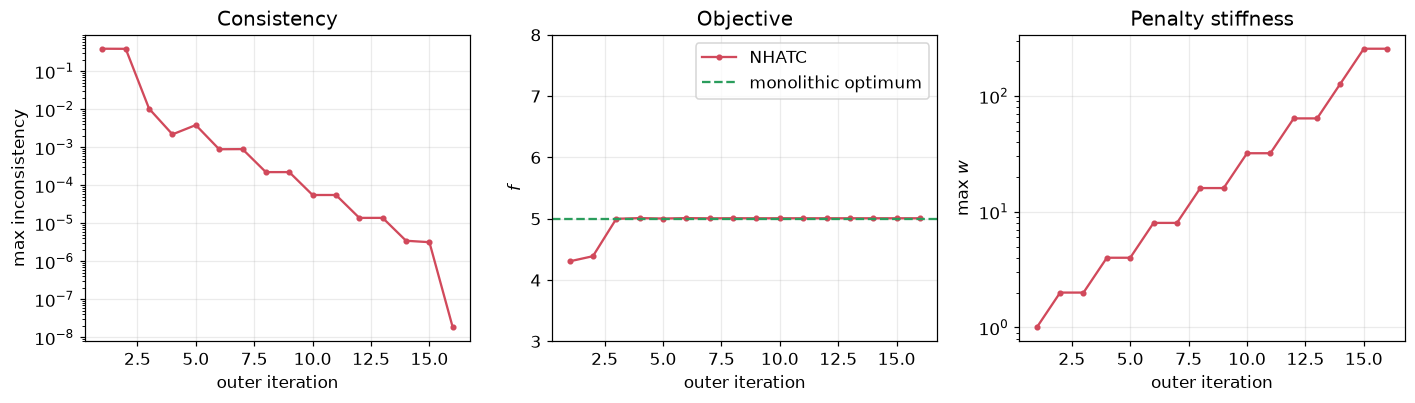

In [5]:
def plot_history(hist, label, color, axes):
    axes[0].semilogy(hist.index, hist["qmax"], "o-", ms=3, color=color, label=label)
    axes[1].plot(hist.index, hist["f"], "o-", ms=3, color=color, label=label)
    axes[2].semilogy(hist.index, hist["wmax"], "o-", ms=3, color=color, label=label)


fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
plot_history(nh, "NHATC", COLORS["nhatc"], axes)
axes[1].axhline(F_REF, color=COLORS["ref"], ls="--", label="monolithic optimum")
axes[0].set(xlabel="outer iteration", ylabel="max inconsistency", title="Consistency")
axes[1].set(xlabel="outer iteration", ylabel="$f$", title="Objective", ylim=(3, 8))
axes[2].set(xlabel="outer iteration", ylabel=r"max $w$", title="Penalty stiffness")
axes[1].legend()
plt.tight_layout()
plt.show()

---
## 4. ATC: a manager and two teams

ATC adds a **system** problem that owns the shared variable $u$ and the coupling targets
$a^t, b^t$, and holds the system part of the objective. Each subsystem tries to match the
targets it receives:

$$
\begin{aligned}
\text{System}:\ \min_{u, a^t, b^t}\ & u + a^t + b^t + \phi_1\big(u_1 - u,\ \hat a - a^t\big) + \phi_2\big(u_2 - u,\ \hat b - b^t\big) \\
\text{SP}_1:\ \min_{u_1, v}\ & v + \phi_1\big(u_1 - u,\ \hat a - a^t\big), \qquad \hat a = \mathcal{U}_1(u_1, v; b^t) \\
\text{SP}_2:\ \min_{u_2, w}\ & \phi_2\big(u_2 - u,\ \hat b - b^t\big) \quad \text{s.t. } w + \hat b - 10 \le 0, \qquad \hat b = \mathcal{U}_2(u_2, w; a^t)
\end{aligned}
$$

One outer iteration solves SP1 and SP2 (independent: they could run in parallel), then the
system problem, then updates the weights.

In [6]:
def atc(beta=2.0, gamma=0.25, w0=3.0, max_outer=150, tol=1e-6):
    u, at, bt = 1.0, 1.0, 1.0                       # system: shared variable and coupling targets
    u1, v, u2, w = 1.0, 1.0, 1.0, 1.0               # subsystems: copies of u and local variables
    pen1, pen2 = Penalty(["u", "a"], w0), Penalty(["u", "b"], w0)
    hist = []
    for k in range(1, max_outer + 1):
        # --- subsystems (independent of each other) ---
        u1, v = slsqp(lambda z: z[1] + pen1(u=z[0] - u, a=U1(z[0], z[1], bt) - at), [u1, v], [(LO, HI)] * 2,
                      [{"type": "ineq", "fun": lambda z: U1(z[0], z[1], bt) - C_LO}])
        a_hat = U1(u1, v, bt)
        u2, w = slsqp(lambda z: pen2(u=z[0] - u, b=U2(z[0], z[1], at) - bt), [u2, w], [(LO, HI)] * 2,
                      [{"type": "ineq", "fun": lambda z: 10.0 - z[1] - U2(z[0], z[1], at)},
                       {"type": "ineq", "fun": lambda z: U2(z[0], z[1], at) - C_LO}])
        b_hat = U2(u2, w, at)
        # --- system ---
        u, at, bt = slsqp(lambda z: z[0] + z[1] + z[2] + pen1(u=u1 - z[0], a=a_hat - z[1])
                          + pen2(u=u2 - z[0], b=b_hat - z[2]), [u, at, bt], [(LO, HI), (C_LO, HI), (C_LO, HI)])
        # --- coordination ---
        h1, h2 = {"u": u1 - u, "a": a_hat - at}, {"u": u2 - u, "b": b_hat - bt}
        pen1.update(h1, beta, gamma)
        pen2.update(h2, beta, gamma)
        q = max(abs(x) for x in [*h1.values(), *h2.values()])
        hist.append(dict(k=k, f=u + v + at + bt, qmax=q, g=w + b_hat - 10,
                         wmax=max(*pen1.w.values(), *pen2.w.values()), u=u, v=v, w=w, a_t=at, b_t=bt))
        if q < tol:
            break
    return pd.DataFrame(hist).set_index("k")


at_hist = atc()
print(f"ATC: {len(at_hist)} outer iterations, f = {at_hist['f'].iloc[-1]:.5f} (reference {F_REF}), "
      f"max inconsistency = {at_hist['qmax'].iloc[-1]:.1e}, g = {at_hist['g'].iloc[-1]:+.1e}")
at_hist[["f", "qmax", "u", "v", "w", "a_t", "b_t"]].tail(3)

ATC: 16 outer iterations, f = 5.12819 (reference 4.98933), max inconsistency = 4.1e-07, g = -3.6e-15


,f,qmax,u,v,w,a_t,b_t
k,,,,,,,
14,5.12818,1.65139e-05,1.38405,0.43448,7.20838,0.518031,2.79162
15,5.12819,6.34145e-06,1.38405,0.434476,7.20837,0.51803,2.79163
16,5.12819,4.06972e-07,1.38405,0.434476,7.20836,0.518029,2.79164


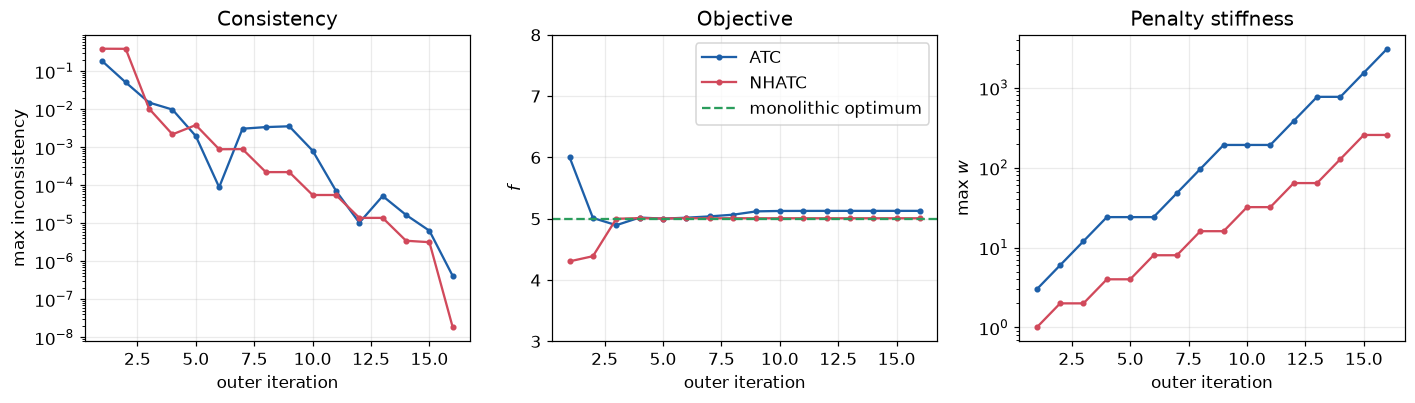

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
plot_history(at_hist, "ATC", COLORS["atc"], axes)
plot_history(nh, "NHATC", COLORS["nhatc"], axes)
axes[1].axhline(F_REF, color=COLORS["ref"], ls="--", label="monolithic optimum")
axes[0].set(xlabel="outer iteration", ylabel="max inconsistency", title="Consistency")
axes[1].set(xlabel="outer iteration", ylabel="$f$", title="Objective", ylim=(3, 8))
axes[2].set(xlabel="outer iteration", ylabel=r"max $w$", title="Penalty stiffness")
axes[1].legend()
plt.tight_layout()
plt.show()

Both schemes reach a **consistent** design (all disagreements below $10^{-6}$), but not exactly
the monolithic optimum. This is typical: once the penalty is stiff, the subproblems care more
about agreeing than about the objective, and the outer loop stops as soon as they agree. The
slides' ATC example (7.108 with DFO subproblems) shows the same effect, larger.

---
## 5. The knobs: $\beta$, and the initial weights

### Penalty growth $\beta$

A large $\beta$ stiffens the penalty quickly: consistency arrives in few iterations, but the
optimizer has less time to improve the objective. A small $\beta$ is slower but more accurate.

In [8]:
rows = []
for beta in [1.1, 1.2, 1.5, 2.0, 3.0]:
    for name, run in [("NHATC", nhatc), ("ATC", atc)]:
        h = run(beta=beta)
        rows.append(dict(method=name, beta=beta, outer_iterations=len(h), f=h["f"].iloc[-1],
                         gap_to_optimum=h["f"].iloc[-1] - F_REF, max_inconsistency=h["qmax"].iloc[-1]))
sweep = pd.DataFrame(rows).set_index(["method", "beta"]).sort_index()
sweep

outer_iterations       f  gap_to_optimum  max_inconsistency
method beta                                                             
ATC    1.1                150 20.1319         15.1425             3.4054
       1.2                 22 5.53673        0.547401        6.81589e-07
       1.5                 14 5.08901       0.0996811        9.11499e-07
       2                   16 5.12819        0.138864        4.06972e-07
       3                   11 5.01969        0.030356        5.45493e-07
NHATC  1.1                 26 4.99047      0.00114254        6.68601e-07
       1.2                 19 4.99431      0.00498154        2.23731e-07
       1.5                 13 4.99947        0.010142        1.72643e-07
       2                   16 5.00754       0.0182089        1.81365e-08
       3                   12 5.01466       0.0253332        4.10691e-07

NHATC shows the textbook trade-off: the gap to the optimum grows steadily with $\beta$, and
$\beta = 1.1$ needs the most iterations. ATC is less regular on this problem: its subsystem 1
only minimizes $v$, so while the penalty is soft it is tempted to wander. At $\beta = 1.1$ the
penalty grows so slowly that ATC never recovers (150 iterations, still inconsistent); the next
experiment shows the mechanism.

### Initial weights $\mathbf{w}^{(0)}$

The problem is **non-convex**, so the coordination can also get stuck. Start ATC with soft
penalties, $w^{(0)} = 1$ instead of $3$:

In [9]:
soft = atc(w0=1.0)
print(f"ATC with w0 = 1: {len(soft)} outer iterations, f = {soft['f'].iloc[-1]:.3f}, "
      f"max inconsistency = {soft['qmax'].iloc[-1]:.2f}, max w = {soft['wmax'].iloc[-1]:.1e}")
soft[["f", "qmax", "u", "v", "w", "wmax"]].iloc[[0, 1, 2, 5, 10, -1]]

ATC with w0 = 1: 150 outer iterations, f = 20.110, max inconsistency = 0.74, max w = 7.1e+44


,f,qmax,u,v,w,wmax
k,,,,,,
1,3.69958,0.5,1.1581,1.11385,8.17237,1
2,16.3933,4.39765,5.60235,0.690994,1.00208,2
3,18.4377,1.67899,8.32101,0.0166391,1.00108,4
6,20.1111,1.09892,10,0.0110517,1.00108,32
11,20.1111,1.09891,10,0.0110517,1.00109,1024
150,20.1101,0.739537,9.999,0.0110517,1.56365,7.13624e+44


In the first iterations the penalty is too soft to matter, so subsystem 1 freely drives $v$
down (its only objective) and pushes $u_1$ to its upper bound to keep $\hat a$ feasible. The
system follows, and by the time the penalty is stiff the iterates sit in a corner where the
subproblems' solvers can no longer make progress: the weights explode (to $10^{44}$) while the
inconsistency stays near $1$. Two practical rules follow:

1. **Scale and initialize** the penalty so that it matters from the first iteration.
2. **Never trust a distributed run that stopped on its budget**: check the final inconsistency
   and compare against a monolithic reference whenever you can.

---
## Exercises

1. **Parallel NHATC.** Change `nhatc` so that SP2 uses SP1's values from the **previous**
   outer iteration (Jacobi instead of Gauss-Seidel over subproblems). How many more outer
   iterations does it need? What would you gain on two machines?
2. **Objective allocation.** In `nhatc`, move the term $\hat a$ from SP1's objective to SP2's
   (SP2 then sees $a^t$). Does the final $f$ change? Why could it?
3. **Stopping rule.** Add a second stopping test on the change in $f$ between outer
   iterations. Does it change the accuracy/iterations trade-off in the $\beta$ sweep?
4. **Rescue the soft start.** Keep $w^{(0)} = 1$ in ATC but start the system targets at
   $a^t = 1$, $b^t = 3$ (close to the MDA solution at $\mathbf{x} = [1,1,1]$). Does ATC converge now?

---
## Takeaways

1. Distributed MDO gives each discipline its own optimizer, with **copies** of shared variables
   and **targets** for coupling variables, tied together by consistency constraints.
2. The augmented Lagrangian penalty $\mathbf{v}^\mathrm{T}\mathbf{h} + \|\mathbf{w}\circ\mathbf{h}\|^2$ and the
   method-of-multipliers updates drive the disagreements to zero over the outer iterations.
3. ATC has a system problem that sets targets; NHATC lets the subproblems negotiate
   directly. DMDO implements NHATC.
4. $\beta$ trades speed for accuracy; initial weights and scaling decide whether a non-convex
   problem converges at all. Always verify consistency and compare to a reference.